# Imports

In [2]:
import numpy as np
import requests
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader, random_split
import torch
import torch.nn as nn
from torch.nn import functional as F

from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

# Add a test set

In [4]:
# download and tokenize the text
text = requests.get('https://www.gutenberg.org/files/35/35-0.txt').text
tm_tokens = torch.tensor(tokenizer.encode(text))
len(tm_tokens)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (45295 > 1024). Running this sequence through the model will result in indexing errors


45295

# Hyperparams

In [5]:
seq_len = 8
stride = 2

embed_dim = 128

batch_size = 64

n_vocab = tokenizer.vocab_size

# Create train and test sets

In [6]:
text = requests.get('http://www.gutenberg.org/files/35/35-0.txt').text
tm_tokens = torch.tensor(tokenizer.encode(text))
len(tm_tokens)

45295

In [7]:
class TokenDataset(Dataset):
  def __init__(self, tokens, seq_len=9, stride=4):

    # initialize
    self.inputs  = []
    self.targets = []

    # overlapping sequences of seq_len

    for i in range(0, len(tokens)-seq_len, stride):

      # get c tokens and append to the lists
      self.inputs.append(tokens[i:i+seq_len])
      self.targets.append(tokens[i+1:i+seq_len+1])

  def __len__(self):
    return len(self.inputs)

  def __getitem__(self, idx):
    return self.inputs[idx], self.targets[idx]

In [8]:
# create an instance
token_dataset = TokenDataset(tm_tokens, seq_len, stride)

# split into train and test
train_ratio = .9
train_size  = int(train_ratio * len(token_dataset))
test_size   = len(token_dataset) - train_size

# create train/test subsets
train_dataset, test_dataset = random_split(
    token_dataset, [train_size, test_size]
)

# create DataLoaders
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader  = DataLoader(test_dataset,  batch_size = batch_size, shuffle = False)

print(f'Train set has {train_size:5} sequences.')
print(f'Test set has {test_size:5} sequences.')

Train set has 20379 sequences.
Test set has  2265 sequences.


# Model

In [9]:
# Model
class Model(nn.Module):
  def __init__(self):
    super().__init__()

    self.embedding = nn.Embedding(n_vocab, embed_dim)
    self.gelu      = nn.GELU()
    self.linear    = nn.Linear(embed_dim, n_vocab)

  def forward(self, x):
    x = self.embedding(x)
    x = self.gelu(x)
    x = self.linear(x)
    return F.log_softmax(x, dim = -1)

  def generate(self, tok_x, n_tok_predict = 30):

    for i in range(n_tok_predict):
      output   = self(tok_x)
      logits   = output[:,-1,:] # [B, T, N_VOCAB]
      probs    = torch.exp(logits)
      next_tok = torch.multinomial(probs, num_samples = 1)
      tok_x = torch.cat((tok_x, next_tok), dim = 1)

    return tok_x

In [10]:
model = Model()
X, y = token_dataset[1]
out = model(X)

print(X.shape)
print(y.shape)
print(out.shape)

torch.Size([8])
torch.Size([8])
torch.Size([8, 50257])


In [11]:
print(X)
print(y)

tensor([ 3963,  3336, 21965, 23680,   402,  3843,  1677, 13246])
tensor([ 3336, 21965, 23680,   402,  3843,  1677, 13246,    38])


In [12]:
# confirm the probability distribution

print(torch.sum(torch.exp(out)))
print(torch.min(torch.exp(out)))
print(torch.max(torch.exp(out)))

tensor(8., grad_fn=<SumBackward0>)
tensor(3.5915e-06, grad_fn=<MinBackward1>)
tensor(0.0001, grad_fn=<MaxBackward1>)


# Train

In [13]:
# push the model to the GPU
model = model.to(device)

# create the loss and optimizer functions
loss_function = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr = 0.001, weight_decay = 0.01)

# Check loss function with sizes
X, y = next(iter(train_dataloader))
log_probs = model(X.to(device))

In [15]:
num_epochs = 25

train_losses = []
test_losses = []

for epoch in range(num_epochs):

  # initialize batch losses to accumulate
  epoch_loss = 0

  # loop over batches in the data loader
  for X, y in train_dataloader:

    # move data to GPU
    X, y = X.to(device), y.to(device)

    # clear previous gradients
    model.zero_grad()

    # forward pass
    log_probs = model(X)

    # calculate the losses on the (reshaped) final target word
    log_probs_flat = log_probs.view(-1,log_probs.shape[-1])
    y_flat = y.view(-1)
    loss = loss_function(log_probs_flat, y_flat)

    # backprop
    loss.backward()
    optimizer.step()

    # sum the batch loss
    epoch_loss += loss.item()

  with torch.no_grad():
    test_loss = 0
    for X, y in test_dataloader:
      X, y = X.to(device), y.to(device)
      out = model(X)
      out_flat = out.reshape(-1, out.shape[-1])
      this_loss = loss_function(out_flat, y.view(-1))
      test_loss += this_loss.item()

  # scale by the number of tokens in this dataloader
  train_losses.append(epoch_loss / len(train_dataloader))
  test_losses.append(test_loss / len(test_dataloader))

  # update our progress
  if epoch%2 == 0:
    print(f'Finished epoch {epoch+1:2} with loss {epoch_loss / len(train_dataloader)}')

Finished epoch  1 with loss 4.828444442031525
Finished epoch  3 with loss 3.997153650630604
Finished epoch  5 with loss 3.6317831961712495
Finished epoch  7 with loss 3.4249712112929007
Finished epoch  9 with loss 3.290304036723409
Finished epoch 11 with loss 3.1997273528837487
Finished epoch 13 with loss 3.1405457239539647
Finished epoch 15 with loss 3.102071723967884
Finished epoch 17 with loss 3.0757571910989694
Finished epoch 19 with loss 3.0589233984394135
Finished epoch 21 with loss 3.046860741971055
Finished epoch 23 with loss 3.0376930924418577
Finished epoch 25 with loss 3.0311314192685215


# Eval

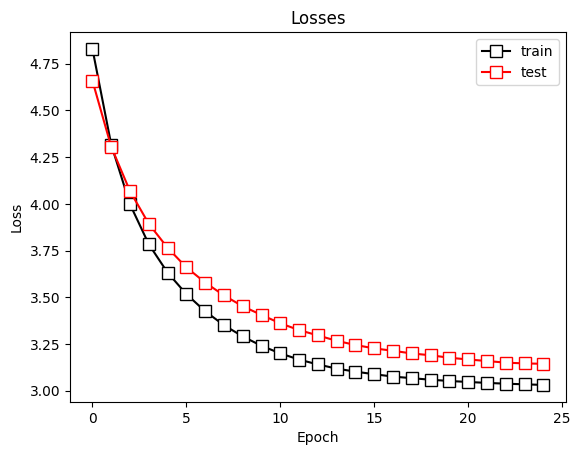

In [18]:
plt.plot(train_losses, 'ks-', markerfacecolor = 'w', markersize = 8, label = 'train')
plt.plot(test_losses, 'rs-', markerfacecolor = 'w', markersize = 8, label = 'test')
plt.gca().set(xlabel = 'Epoch', ylabel = 'Loss')
plt.legend()
plt.title('Losses')
plt.show()